# Toy model: a simple cycle with an escape

This notebook reproduces the analysis of the toy model of the [MaBoSS website](https://maboss.curie.fr).

The model consists of three nodes: A, B and C. A is activated by C and inhibited by B, B is activated by A,
and C can only be degraded, when both A and B are inactive. The transition graph shows a fixed point
[ABC] = [000], and a cycle [101] → [111] → [011] → [001]. At [001], the system can either continue to cycle,
or escape the cycle and reach the fixed point [000]. We explore the dynamics when this escape rate
(the degradation of C) is fast or slow.

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/), and the files `Four_cycle.bnd`,
`Four_cycle_FEscape.cfg`, `Four_cycle_SEscape.cfg` and `Four_cycle_SEscape_long.cfg`, in the same folder as this notebook.

In [1]:
import math
import os
import maboss
import matplotlib.pyplot as plt
from matplotlib.offsetbox import HPacker

# The figures are saved in the "figures" folder
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"savefig.dpi": 150, "savefig.bbox": "tight", "figure.constrained_layout.use": True})

def legend_below():
    """Move the legend of the current figure below the plot, in centered rows of similar widths."""
    figure, legend = plt.gcf(), plt.gca().get_legend()
    handles, labels = legend.legend_handles, [text.get_text() for text in legend.get_texts()]
    legend.remove()
    legend = figure.legend(handles, labels, loc="outside lower center", ncols=1)
    # Matplotlib fills the rows from the left: we rearrange the entries of the legend in centered rows,
    # as few as possible within the width of the plot, and of similar widths
    column = legend._legend_handle_box.get_children()[0]
    entries, column.align = column.get_children(), "center"
    sep = legend.columnspacing * legend.prop.get_size_in_points() * figure.dpi / 72
    widths = [entry.get_bbox(figure.canvas.get_renderer()).width + sep for entry in entries]
    max_width = 0.8 * figure.get_figwidth() * figure.dpi
    for n_rows in range(math.ceil(sum(widths) / max_width), len(entries) + 1):
        rows, row_widths = [[]], [0]
        for entry, width in zip(entries, widths):
            if rows[-1] and row_widths[-1] + width / 2 > sum(widths) / n_rows:
                rows.append([])
                row_widths.append(0)
            rows[-1].append(entry)
            row_widths[-1] += width
        if max(row_widths) <= max_width:
            break
    column._children = [HPacker(sep=sep, align="baseline", children=row) for row in rows]

## The model

The rates of the transitions are given by the parameters `$Au`, `$Ad` and `$escape`, defined in the configuration files.
The parameter `$escape` corresponds to the degradation of C: it is set to 10 in the fast case, and to 0.00001 in the slow case.
All the nodes are initially active.

In [2]:
fast = maboss.load("Four_cycle.bnd", "Four_cycle_FEscape.cfg")
fast.print_bnd()

Node C {


	rate_up = 0.0;
	rate_down = ((NOT A) AND (NOT B)) ? $escape : 0.0 ;
}
Node A {


	rate_up = (C AND (NOT B))  ? $Au : 0.0;
	rate_down = B ? $Ad : 0.0;
}

Node B {


	rate_up = A ? $Au : 0.0;
	rate_down = A ? 0.0 : $Ad ;
}


## Fast escape

We plot the probabilities of the network states as functions of time. `<nil>` is the state where all the
nodes are inactive: the fixed point [000]. Its probability tends to 1.

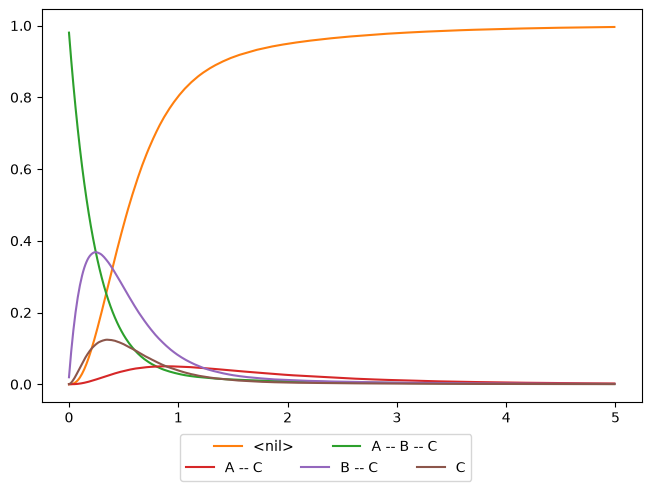

In [3]:
result_fast = fast.run()
result_fast.plot_trajectory()
legend_below()
plt.savefig("figures/toy_fast_escape.png")

Both the entropy (H) and the transition entropy (TH) tend to 0.

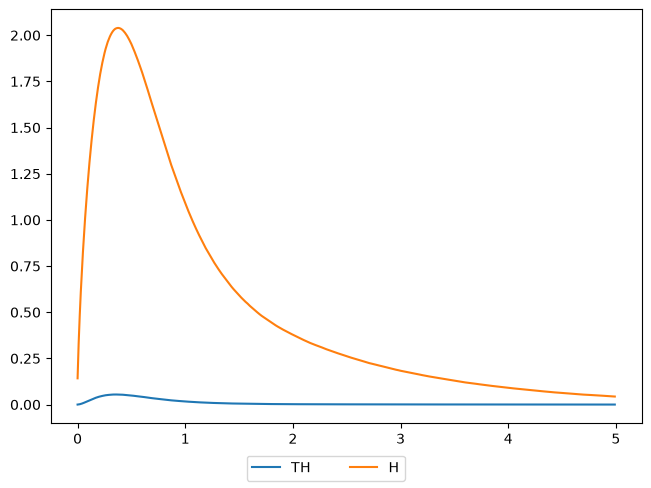

In [4]:
result_fast.plot_entropy_trajectory()
legend_below()
plt.savefig("figures/toy_fast_escape_entropy.png")

## Slow escape

When looking at the early response, the probabilities do not show the presence of the fixed point:
the system seems stuck in a limit cycle.

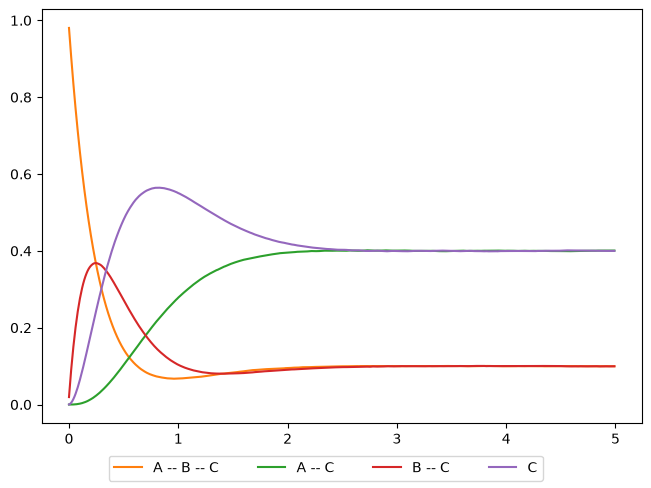

In [5]:
slow = maboss.load("Four_cycle.bnd", "Four_cycle_SEscape.cfg")
result_slow = slow.run()
result_slow.plot_trajectory()
legend_below()
plt.savefig("figures/toy_slow_escape.png")

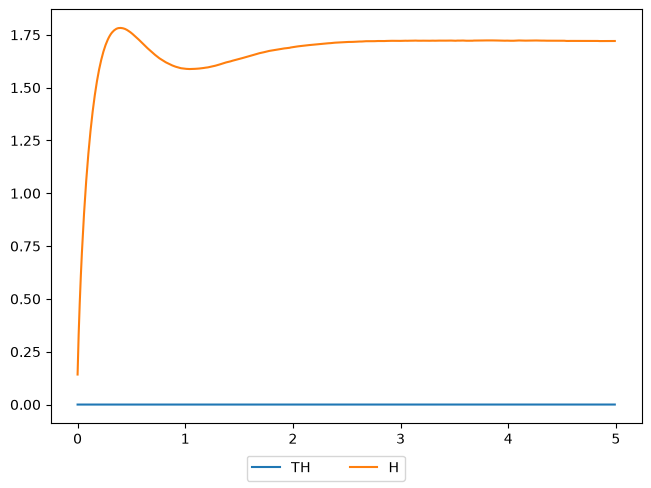

In [6]:
result_slow.plot_entropy_trajectory()
legend_below()
plt.savefig("figures/toy_slow_escape_entropy.png")

It is only after a long time that the system reaches the fixed point, and that the entropy and transition
entropy reach 0. The two simulations show both the transient and the asymptotic behaviours.

*This simulation takes a few minutes.*

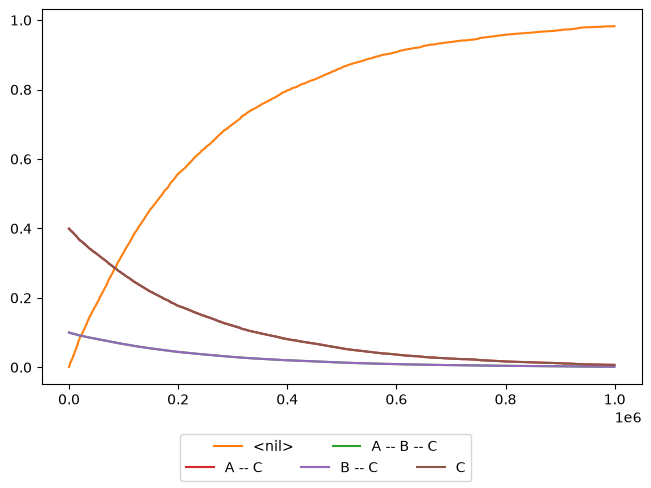

In [7]:
slow_long = maboss.load("Four_cycle.bnd", "Four_cycle_SEscape_long.cfg")
result_slow_long = slow_long.run()
result_slow_long.plot_trajectory()
legend_below()
plt.savefig("figures/toy_slow_escape_long.png")

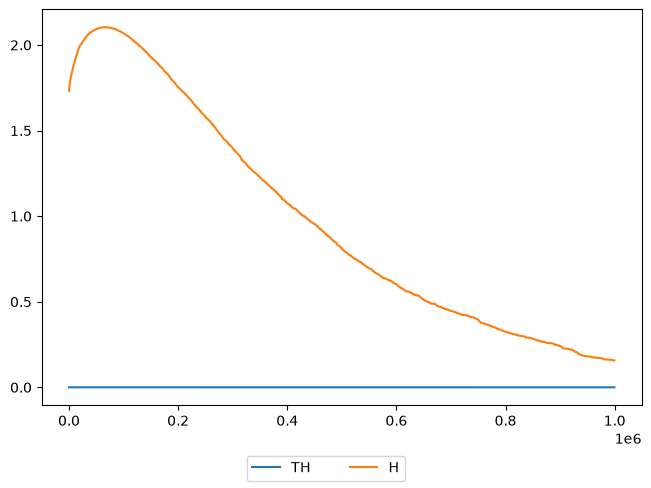

In [8]:
result_slow_long.plot_entropy_trajectory()
legend_below()
plt.savefig("figures/toy_slow_escape_long_entropy.png")